In [1]:
!pip install mediapipe opencv-python scikit-image torchmetrics facenet-pytorch

import os
import math
import random
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import Subset
from torch.utils.data import random_split

from torchvision import transforms
from torchvision.datasets import CelebA
from torchvision.models import vgg16
import torchvision.transforms.functional as TF

import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2

from facenet_pytorch import MTCNN, InceptionResnetV1
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

import matplotlib.pyplot as plt

from PIL import Image

import shutil

INFO: pip is looking at multiple versions of facenet-pytorch to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 79.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 9.0 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.0 which is incompatible.


In [2]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 7
IMG_COUNT_LIMIT = None
DOWNSAMPLE_FACTORS = [1.2, 1.4]
kaggle_celeba_path = "/kaggle/input/celeba-dataset/img_align_celeba/img_align_celeba"
kaggle_celeba_aligned_path = "/kaggle/working/celeba-aligned"
kaggle_lfw_path = "/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"

In [3]:
mtcnn = MTCNN(
    image_size=IMG_SIZE,
    margin=20,
    post_process=True,
    device=DEVICE
)

def align_and_save_faces(
    input_root,
    output_root,
    max_images=None
):

    if os.path.exists(output_root):
        print(f"Cleaning up existing directory: {output_root}")
        shutil.rmtree(output_root)
        
    os.makedirs(output_root, exist_ok=True)

    image_paths = []
    for root, _, files in os.walk(input_root):
        print(len(files))
        for f in files:
            if f.lower().endswith((".jpg", ".png")):
                image_paths.append(os.path.join(root, f))

    if max_images is not None:
        image_paths = image_paths[:max_images]

    for i, path in enumerate(tqdm(image_paths, desc="Aligning faces")):
        try:
            img = Image.open(path).convert("RGB")
            face = mtcnn(img)

            if face is None:
                continue
            
            face = (face + 1) / 2

            out_path = os.path.join(output_root, f"face_{i:06d}.png")
            transforms.ToPILImage()(face).save(out_path)

        except Exception:
            continue

In [4]:
augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.RandomBrightnessContrast(0.2, 0.2, p=0.5),
])

In [5]:
def downsample(img, factor):
    h, w = img.shape[-2:]
    new_h, new_w = int(h / factor), int(w / factor)
    img = F.interpolate(img.unsqueeze(0), size=(new_h, new_w), mode="bilinear")
    img = F.interpolate(img, size=(h, w), mode="bilinear")
    return img.squeeze(0)

def add_gaussian_noise(img, std=0.05):
    noise = torch.randn_like(img) * std
    return torch.clamp(img + noise, 0, 1)

def motion_blur(img, kernel_size=7):
    angle = random.uniform(-30, 30)
    return TF.gaussian_blur(img, kernel_size=kernel_size)

def degrade_image(hr):
    img = hr.clone()

    factor = random.choice([1.2, 1.4])
    img = downsample(img, factor)

    if random.random() < 0.5:
        img = add_gaussian_noise(img, std=0.03)

    if random.random() < 0.3:
        img = motion_blur(img, kernel_size=7)

    return img


class FaceRestorationDataset(Dataset):
    def __init__(self, image_paths, img_size=IMG_SIZE):
        self.image_paths = image_paths
        self.img_size = img_size

        self.base_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        hr = self.base_transform(img)

        lr_clean = downsample(hr, random.choice([1.2, 1.4]))
        lr_noisy = degrade_image(hr)

        return lr_noisy, hr, lr_clean

In [6]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        def C(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.ReLU(inplace=True)
            )

        self.enc1 = C(3, 64)
        self.enc2 = C(64, 128)
        self.enc3 = C(128, 256)

        self.pool = nn.MaxPool2d(2)

        self.dec3 = C(256 + 128, 128)
        self.dec2 = C(128 + 64, 64)
        self.final = nn.Conv2d(64, 3, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        d3 = F.interpolate(e3, scale_factor=2)
        d3 = self.dec3(torch.cat([d3, e2], 1))

        d2 = F.interpolate(d3, scale_factor=2)
        d2 = self.dec2(torch.cat([d2, e1], 1))

        return torch.sigmoid(self.final(d2))

In [7]:
class RestorationLoss(nn.Module):
    def __init__(self, mode="L1"):
        super().__init__()
        self.loss = nn.L1Loss() if mode == "L1" else nn.MSELoss()

    def forward(self, pred, target):
        return self.loss(pred, target)

def total_loss(sr, hr, lambda_pix=1.0, lambda_id=0.1):
    pix = F.l1_loss(sr, hr)
    idl = identity_loss(sr, hr)
    return lambda_pix * pix + lambda_id * idl

class PerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = vgg16(pretrained=True).features[:16]
        self.vgg = vgg.eval().to(DEVICE)
        for p in self.vgg.parameters():
            p.requires_grad = False

    def forward(self, x, y):
        return F.l1_loss(self.vgg(x), self.vgg(y))

In [8]:
embedder = InceptionResnetV1(pretrained="vggface2").eval().to(DEVICE)


def face_embedding_distance(x, y):
    with torch.no_grad():
        ex = embedder(x)
        ey = embedder(y)
    return F.pairwise_distance(ex, ey).mean().item()

def identity_loss(sr, hr):
    ex = embedder(sr)
    ey = embedder(hr)
    return F.mse_loss(ex, ey)


def compute_metrics(pred, gt):
    pred_np = pred.permute(0, 2, 3, 1).cpu().numpy()
    gt_np = gt.permute(0, 2, 3, 1).cpu().numpy()

    psnr = np.mean([
        peak_signal_noise_ratio(gt_np[i], pred_np[i], data_range=1.0)
        for i in range(len(pred_np))
    ])

    ssim = np.mean([
        structural_similarity(gt_np[i], pred_np[i], channel_axis=-1, data_range=1.0)
        for i in range(len(pred_np))
    ])

    emb = face_embedding_distance(pred, gt)
    return psnr, ssim, emb

  0%|          | 0.00/107M [00:00<?, ?B/s]

In [9]:
def evaluate(model, loader):
    model.eval()

    psnr_list, ssim_list, emb_list = [], [], []

    with torch.no_grad():
        for lr, hr, _ in loader:
            lr, hr = lr.to(DEVICE), hr.to(DEVICE)
            sr = model(lr)

            psnr, ssim, emb = compute_metrics(sr, hr)
            psnr_list.append(psnr)
            ssim_list.append(ssim)
            emb_list.append(emb)

    return (
        np.mean(psnr_list),
        np.mean(ssim_list),
        np.mean(emb_list)
    )

In [10]:
def train_model(train_ds, val_ds):
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

    model = UNet().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), 1e-4)
    scaler = torch.cuda.amp.GradScaler()
    criterion = RestorationLoss("L1")
    best_psnr = 0

    for epoch in range(EPOCHS):
        model.train()
        train_loss = 0.0

        for lr, hr, _ in train_loader:
          lr = lr.to(DEVICE, non_blocking=True)
          hr = hr.to(DEVICE, non_blocking=True)

          optimizer.zero_grad()

          with torch.cuda.amp.autocast():
              sr = model(lr)
              train_loss = total_loss(sr, hr)

          scaler.scale(train_loss).backward()
          scaler.step(optimizer)
          scaler.update()

        train_loss /= len(train_loader)

        val_psnr, val_ssim, val_emb = evaluate(model, val_loader)

        if val_psnr > best_psnr:
          best_psnr = val_psnr
          save_model(model, optimizer, epoch)

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val PSNR: {val_psnr:.2f} | "
            f"Val SSIM: {val_ssim:.4f} | "
            f"Val Emb: {val_emb:.4f}"
        )

    return model

In [11]:
def load_aligned_faces_from_folder(
    root,
    max_images=None,
    val_ratio=0.2
):
    image_paths = [
        os.path.join(root, f)
        for f in os.listdir(root)
        if f.lower().endswith((".jpg", ".png"))
    ]

    if max_images is not None:
        image_paths = image_paths[:max_images]

    random.shuffle(image_paths)

    val_size = int(len(image_paths) * val_ratio)
    train_paths = image_paths[val_size:]
    val_paths = image_paths[:val_size]

    train_ds = FaceRestorationDataset(train_paths)
    val_ds = FaceRestorationDataset(val_paths)

    return train_ds, val_ds

In [12]:
def visualize_results(model, dataset, num_images=3):
    model.eval()
    indices = random.sample(range(len(dataset)), num_images)

    plt.figure(figsize=(16, 4 * num_images))

    with torch.no_grad():
        for i, idx in enumerate(indices):
            lr_noisy, hr, lr_clean = dataset[idx]

            lr_noisy = lr_noisy.unsqueeze(0).to(DEVICE)
            sr = model(lr_noisy)

            # Convert to HWC for plotting
            hr_img = hr.permute(1, 2, 0).cpu()
            lr_clean_img = lr_clean.permute(1, 2, 0).cpu()
            lr_noisy_img = lr_noisy.squeeze().permute(1, 2, 0).cpu()
            sr_img = sr.squeeze().permute(1, 2, 0).cpu()

            images = [
                (hr_img, "Original (HR)"),
                (lr_clean_img, "Downsampled (clean LR)"),
                (lr_noisy_img, "Noisy Input (model sees this)"),
                (sr_img, "Reconstructed (SR)"),
            ]

            for j, (img, title) in enumerate(images):
                plt.subplot(num_images, 4, i * 4 + j + 1)
                plt.imshow(img)
                plt.axis("off")
                plt.title(title)

    plt.tight_layout()
    plt.show()

In [13]:
def collect_image_paths(root, exts=(".jpg", ".jpeg", ".png")):
    image_paths = []
    for dirpath, _, filenames in os.walk(root):
        for fname in filenames:
            if fname.lower().endswith(exts):
                image_paths.append(os.path.join(dirpath, fname))
    return image_paths

def load_test_faces_from_folder(
    root,
    max_images=None
):
    image_paths = collect_image_paths(root)

    if len(image_paths) == 0:
        raise RuntimeError(f"No images found under {root}")

    if max_images is not None:
        image_paths = image_paths[:max_images]

    return FaceRestorationDataset(image_paths)


class FaceRestorationTestDataset(torch.utils.data.Dataset):
    def __init__(self, image_dir):
        self.image_paths = [
            os.path.join(image_dir, f)
            for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".png"))
        ]
        self.transform = transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        hr = self.transform(img)
        lr = degrade_image(hr)
        return lr, hr

In [14]:
def save_model(model, optimizer, epoch, path="face_restoration_unet.pth"):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    }, path)

def load_model(model, optimizer=None, path="face_restoration_unet.pth"):
    checkpoint = torch.load(path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    if optimizer is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    return checkpoint["epoch"]

In [15]:
align_and_save_faces(
    input_root=kaggle_celeba_path,
    output_root=kaggle_celeba_aligned_path,
    max_images=IMG_COUNT_LIMIT
)

train_ds, val_ds = load_aligned_faces_from_folder(
    root=kaggle_celeba_aligned_path,
)

train_loader = DataLoader(
    train_ds,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

len(train_ds)

202599


Aligning faces: 100%|██████████| 202599/202599 [1:59:38<00:00, 28.22it/s]


161845

/tmp/ipykernel_23/3872495531.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_23/3872495531.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 01 | Train Loss: 0.0000 | Val PSNR: 35.71 | Val SSIM: 0.9602 | Val Emb: 0.1345
Epoch 02 | Train Loss: 0.0000 | Val PSNR: 37.54 | Val SSIM: 0.9705 | Val Emb: 0.1026
Epoch 03 | Train Loss: 0.0000 | Val PSNR: 37.82 | Val SSIM: 0.9737 | Val Emb: 0.0931
Epoch 04 | Train Loss: 0.0000 | Val PSNR: 38.66 | Val SSIM: 0.9756 | Val Emb: 0.0864
Epoch 05 | Train Loss: 0.0000 | Val PSNR: 39.00 | Val SSIM: 0.9766 | Val Emb: 0.0822
Epoch 06 | Train Loss: 0.0000 | Val PSNR: 38.98 | Val SSIM: 0.9764 | Val Emb: 0.0836
Epoch 07 | Train Loss: 0.0000 | Val PSNR: 39.55 | Val SSIM: 0.9783 | Val Emb: 0.0780


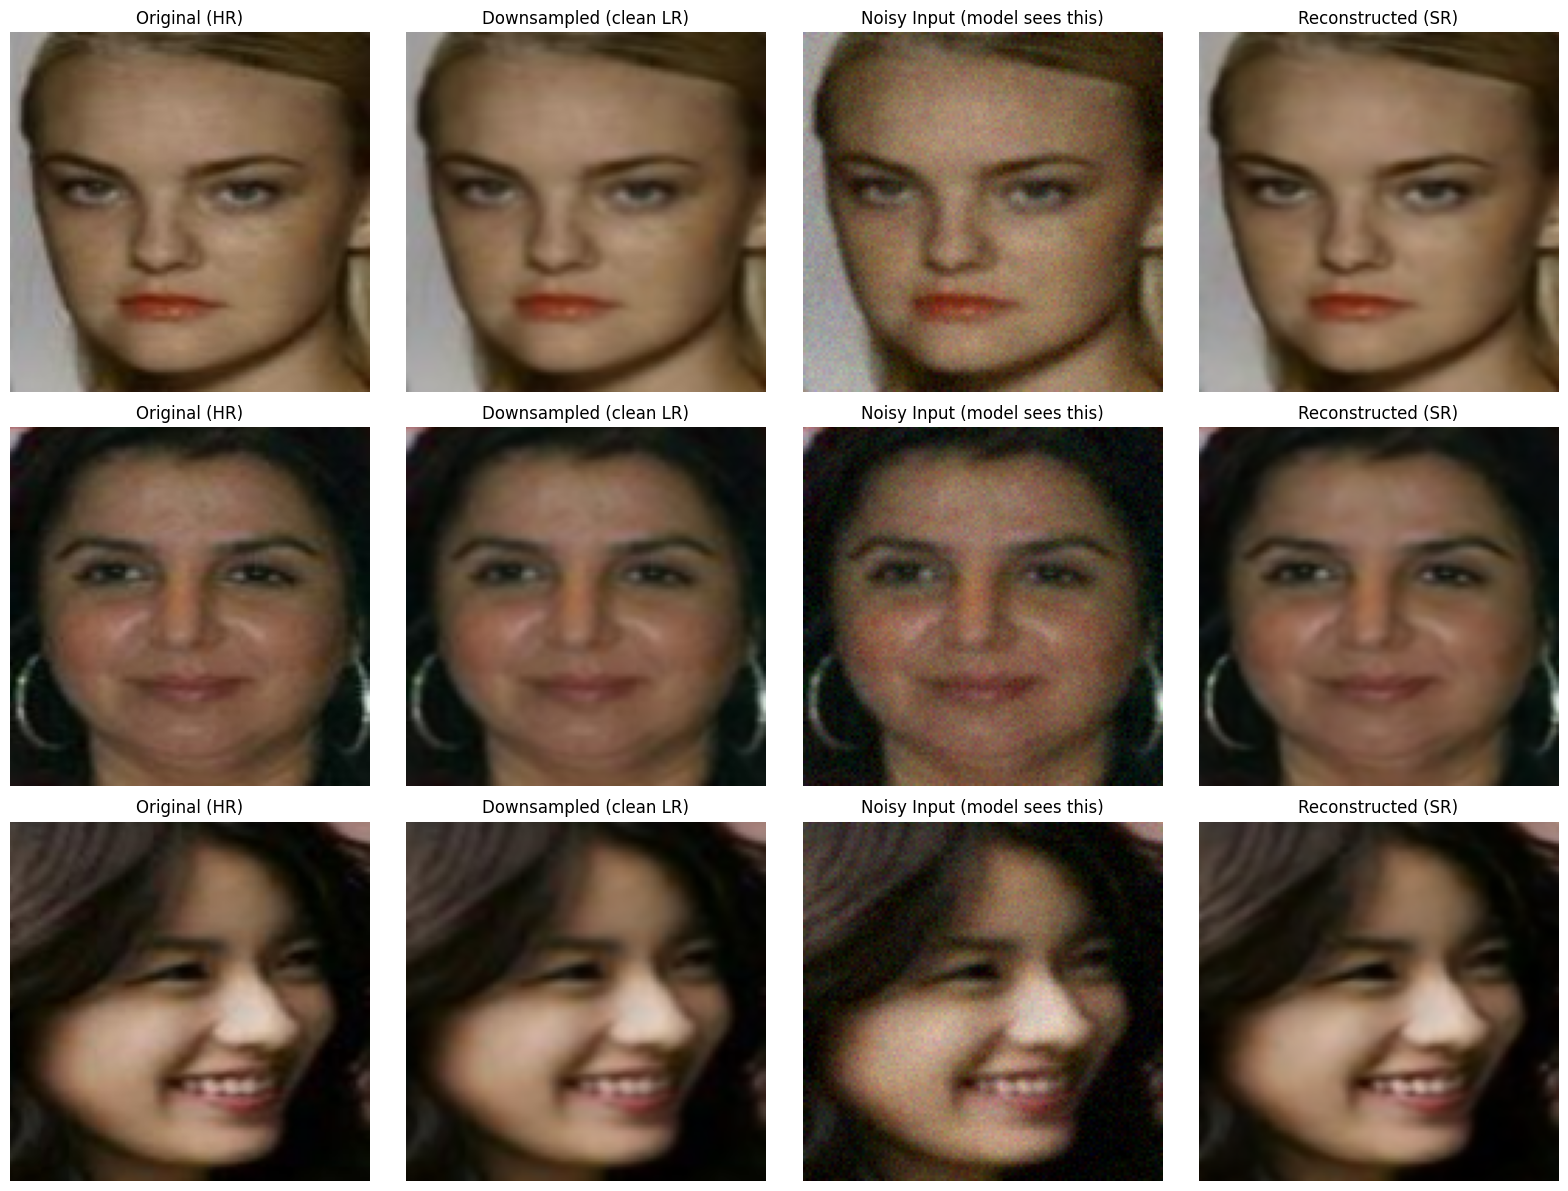

In [16]:
model = train_model(train_ds, val_ds)
visualize_results(model, val_ds, num_images=3)

In [17]:
test_ds = load_test_faces_from_folder(
    root=kaggle_lfw_path,
)

test_loader = DataLoader(
    test_ds,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

len(test_ds)

13233

In [18]:
from skimage.metrics import structural_similarity as ssim_fn

def evaluate_model(model, dataloader):
    model.eval()

    psnr_vals = []
    ssim_vals = []
    emb_vals = []

    with torch.no_grad():
        for lr, hr, _ in tqdm(dataloader, desc="Evaluating"):
            lr = lr.to(DEVICE)
            hr = hr.to(DEVICE)

            sr = model(lr)

            mse = F.mse_loss(sr, hr)
            psnr = 10 * torch.log10(1.0 / mse)
            psnr_vals.append(psnr.item())

            for i in range(sr.size(0)):
                ssim_val = ssim_fn(
                    sr[i].permute(1, 2, 0).cpu().numpy(),
                    hr[i].permute(1, 2, 0).cpu().numpy(),
                    data_range=1.0,
                    channel_axis=-1
                )
                ssim_vals.append(ssim_val)

            emb = face_embedding_distance(sr, hr)
            emb_vals.append(emb)

    return {
        "PSNR": sum(psnr_vals) / len(psnr_vals),
        "SSIM": sum(ssim_vals) / len(ssim_vals),
        "Embedding Distance": sum(emb_vals) / len(emb_vals)
    }

In [19]:
metrics = evaluate_model(model, test_loader)

print("Test results on new dataset:")
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")

Evaluating: 100%|██████████| 1655/1655 [02:07<00:00, 12.96it/s]

Test results on new dataset:
PSNR: 36.8777
SSIM: 0.9767
Embedding Distance: 0.1049


In [20]:
def visualize_test_results(model, dataset, num_images=3):
    model.eval()
    indices = random.sample(range(len(dataset)), num_images)

    fig, axs = plt.subplots(num_images, 3, figsize=(12, 4 * num_images))

    for i, idx in enumerate(indices):
        lr, hr, _ = dataset[idx]

        with torch.no_grad():
            sr = model(lr.unsqueeze(0).to(DEVICE)).cpu().squeeze(0)

        imgs = [lr, sr, hr]
        titles = ["Degraded Input", "Restored", "Ground Truth"]

        for j, (img, title) in enumerate(zip(imgs, titles)):
            axs[i, j].imshow(img.permute(1, 2, 0).clamp(0, 1))
            axs[i, j].set_title(title)
            axs[i, j].axis("off")

    plt.tight_layout()
    plt.show()

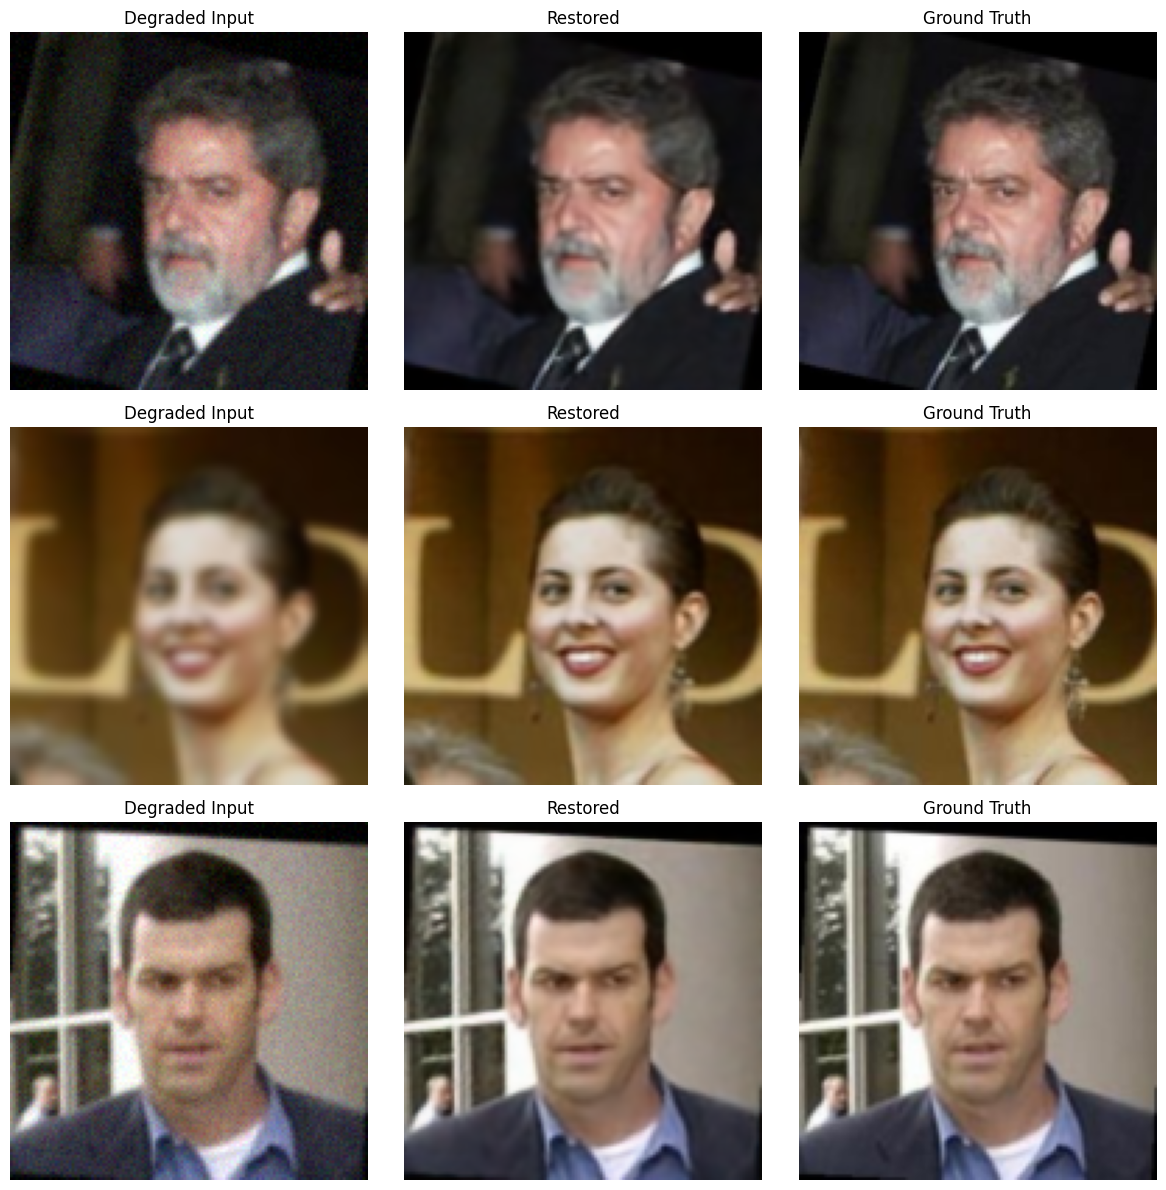

In [21]:
visualize_test_results(model, test_ds, num_images=3)